# Базовая модель

Блок 3.1 требований: простая модель для выбранного алгоритма, разделение на
обучающую и тестовую выборки, базовые метрики классификации, анализ ошибок.

Данные: features.vs_student_semester, единица наблюдения «студент, начало
семестра», признаки со срезом на дату (см. notebooks/01). Отдельным референсом
считается действующее правило вуза «две и более задолженности»: с ним модель
сравнивается уже здесь, полное сравнение входит в гипотезу H1 (notebooks/03).

Правило разделения выборок (docs/experiment_plan.md, раздел 1): по студентам
и по времени. Обучение на когортах поступления 2019-2022, проверка на когорте
2023 (out-of-time по набору). UCI не содержит времени, там используется
стратифицированное случайное разделение 70/30 с фиксированным seed.

In [1]:
import os, sys
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)
sys.path.insert(0, os.path.join(ROOT, 'src'))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score, confusion_matrix,
                             roc_curve, precision_recall_curve)
from utils.db import engine

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid', palette='deep')
eng = engine()
SEED = 20261120

def metrics_at(y_true, proba, name, top_k=100):
    y_pred = (proba >= 0.5).astype(int)
    order = np.argsort(-proba)
    top = y_true.iloc[order[:top_k]] if hasattr(y_true, 'iloc') else y_true[order[:top_k]]
    total_pos = y_true.sum()
    return {
        'модель': name,
        'ROC-AUC': round(roc_auc_score(y_true, proba), 3),
        'PR-AUC': round(average_precision_score(y_true, proba), 3),
        'Brier': round(brier_score_loss(y_true, proba), 3),
        'precision@0.5': round(precision_score(y_true, y_pred, zero_division=0), 3),
        'recall@0.5': round(recall_score(y_true, y_pred, zero_division=0), 3),
        f'recall@{top_k}': round(top.sum() / total_pos, 3) if total_pos else 0.0,
        f'precision@{top_k}': round(top.mean(), 3),
    }

print('готово')

готово


## 1. Данные и разделение выборок

Точки наблюдения, у которых семестр обучения ещё не начат из-за позднего
приказа о зачислении, в данных отсутствуют по построению. Признаки на дату
наблюдения не содержат сведений о будущем (срез обеспечен слоем features).

Когорта поступления подтягивается из витрины студента: она известна на дату
наблюдения, поэтому соединение не создаёт утечки.

In [2]:
feat = pd.read_sql('SELECT * FROM features.vs_student_semester', eng)
cohort = pd.read_sql('SELECT student_id, admission_year FROM cleaned.vs_students', eng)
feat = feat.merge(cohort, on='student_id', how='left')

train = feat[feat.admission_year <= 2022]
test = feat[feat.admission_year == 2023]
print('всего точек:', len(feat))
print(f"train (наборы 2019-2022): {len(train)}, положительных {train.target.mean():.1%}")
print(f"test (набор 2023): {len(test)}, положительных {test.target.mean():.1%}")

всего точек: 24343
train (наборы 2019-2022): 19526, положительных 3.4%
test (набор 2023): 4817, положительных 3.7%


In [3]:
DROP_COLS = ['student_id', 'program_id', 'group_code', 'observation_date',
             'dropout_reason', 'target', 'admission_year']
BOOL_COLS = ['is_non_local', 'hostel', 'privilege', 'medal', 'on_leave']
CAT_COLS = ['gender', 'region', 'study_form', 'basis', 'previous_education', 'faculty']
NUM_COLS = [c for c in feat.columns
            if c not in DROP_COLS + CAT_COLS and c not in BOOL_COLS]

def prepare(df):
    X = df.drop(columns=DROP_COLS).copy()
    for c in BOOL_COLS:
        X[c] = X[c].astype('float')
    return X

X_train, y_train = prepare(train), train['target'].astype(int)
X_test, y_test = prepare(test), test['target'].astype(int)
print('признаков:', X_train.shape[1], 'числовых:', len(NUM_COLS) + len(BOOL_COLS), 'категориальных:', len(CAT_COLS))

признаков: 35 числовых: 29 категориальных: 6


## 2. Базовая модель: логистическая регрессия

Дисбаланс классов (3.4% положительных) осознанно не компенсируется весами:
на базовом шаге показываем, как при таком балансе выглядит стандартный
порог 0.5, а рабочая метрика списка риска это recall@100.

In [4]:
num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
pre = ColumnTransformer([
    ('num', num_pipe, NUM_COLS + BOOL_COLS),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20), CAT_COLS),
])
logreg = Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=2000, random_state=SEED))])
logreg.fit(X_train, y_train)
proba_lr = logreg.predict_proba(X_test)[:, 1]
row_lr = metrics_at(y_test.reset_index(drop=True), proba_lr, 'логистическая регрессия')
pd.DataFrame([row_lr])

,модель,ROC-AUC,PR-AUC,Brier,precision@0.5,recall@0.5,recall@100,precision@100
0,логистическая регрессия,0.65,0.079,0.036,0.0,0.0,0.072,0.13


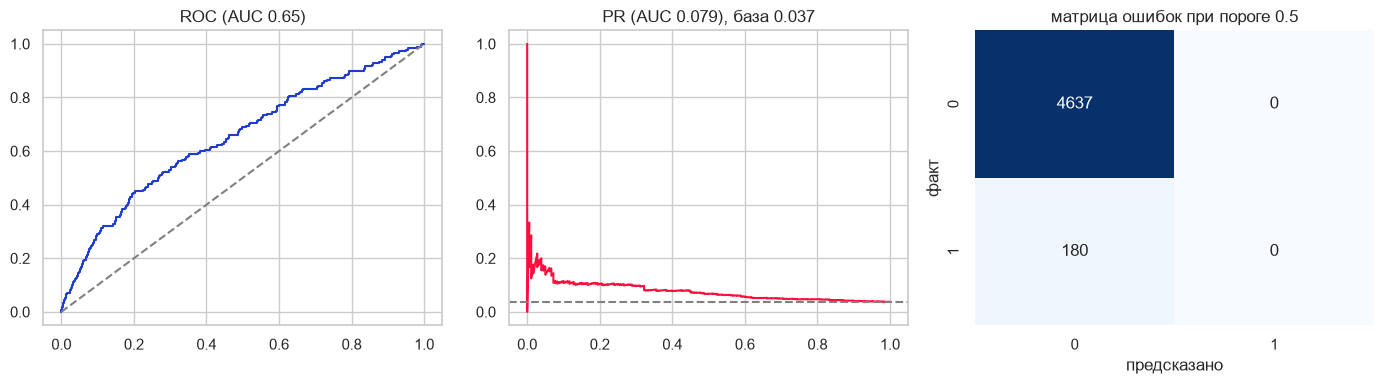

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fpr, tpr, _ = roc_curve(y_test, proba_lr)
axes[0].plot(fpr, tpr, color='#1E3CD4')
axes[0].plot([0, 1], [0, 1], ls='--', c='grey')
axes[0].set_title(f"ROC (AUC {row_lr['ROC-AUC']})")
prec, rec, _ = precision_recall_curve(y_test, proba_lr)
axes[1].plot(rec, prec, color='#FC0F3C')
axes[1].axhline(y_test.mean(), ls='--', c='grey')
axes[1].set_title(f"PR (AUC {row_lr['PR-AUC']}), база {y_test.mean():.3f}")
cm = confusion_matrix(y_test, (proba_lr >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2], cbar=False)
axes[2].set_title('матрица ошибок при пороге 0.5')
axes[2].set_xlabel('предсказано'); axes[2].set_ylabel('факт')
plt.tight_layout()
plt.show()

### Бизнес-правило как референс

Правило «две и более открытых задолженности» не обучается, оно фиксировано
и применяется к той же тестовой выборке.

In [6]:
proba_rule = (X_test['debts_open'] >= 2).astype(float).values
row_rule = metrics_at(y_test.reset_index(drop=True), proba_rule, 'правило: 2+ долга')
pd.DataFrame([row_rule])

,модель,ROC-AUC,PR-AUC,Brier,precision@0.5,recall@0.5,recall@100,precision@100
0,правило: 2+ долга,0.523,0.04,0.147,0.051,0.167,0.044,0.08


In [7]:
tree = Pipeline([('pre', pre), ('clf', DecisionTreeClassifier(max_depth=4, random_state=SEED))])
tree.fit(X_train, y_train)
proba_tree = tree.predict_proba(X_test)[:, 1]
row_tree = metrics_at(y_test.reset_index(drop=True), proba_tree, 'дерево решений (глубина 4)')
pd.DataFrame([row_rule, row_lr, row_tree]).set_index('модель')

,ROC-AUC,PR-AUC,Brier,precision@0.5,recall@0.5,recall@100,precision@100
модель,,,,,,,
правило: 2+ долга,0.523,0.040,0.147,0.051,0.167,0.044,0.08
логистическая регрессия,0.650,0.079,0.036,0.000,0.000,0.072,0.13
дерево решений (глубина 4),0.619,0.060,0.037,0.143,0.006,0.056,0.10


## 3. Анализ ошибок логистической регрессии

In [8]:
test_df = test.reset_index(drop=True).copy()
test_df['proba'] = proba_lr
test_df['pred'] = (proba_lr >= 0.5).astype(int)
false_pos = test_df[(test_df.pred == 1) & (test_df.target == 0)].nlargest(5, 'proba')
false_neg = test_df[(test_df.pred == 0) & (test_df.target == 1)].nsmallest(5, 'proba')
cols = ['student_id', 'observation_date', 'semester_no', 'gpa_last', 'debts_open',
        'overdue_max', 'exam_score', 'proba', 'target']
print('ложные тревоги с наибольшей уверенностью модели:')
if false_pos.empty:
    print('при пороге 0.5 ложных тревог нет: модель ни одну точку не отнесла к положительному классу')
else:
    display(false_pos[cols])
print('пропущенные риски с наименьшей уверенностью модели:')
display(false_neg[cols])

ложные тревоги с наибольшей уверенностью модели:
при пороге 0.5 ложных тревог нет: модель ни одну точку не отнесла к положительному классу
пропущенные риски с наименьшей уверенностью модели:


,student_id,observation_date,semester_no,gpa_last,debts_open,overdue_max,exam_score,proba,target
2626,aacda3ef-1d9a-42da-b8d4-49c319090171,2027-09-01,9,3.70,0,NaN,50.5,0.004814,1
1252,c0d672ed-a27b-4408-8d95-c5be7416079f,2027-02-05,8,4.33,0,22.0,77.3,0.005078,1
1986,3ac9aefa-c6d7-40f3-bb8d-24a7141b179e,2028-02-05,10,3.67,0,37.0,51.5,0.006561,1
4464,afb7deda-0877-4307-9d27-df3baa7f5574,2026-09-01,7,4.57,0,43.0,78.5,0.008182,1
1675,4a5df831-2f03-4433-9e83-a57db10ef800,2027-02-05,8,3.67,0,119.0,64.9,0.008686,1


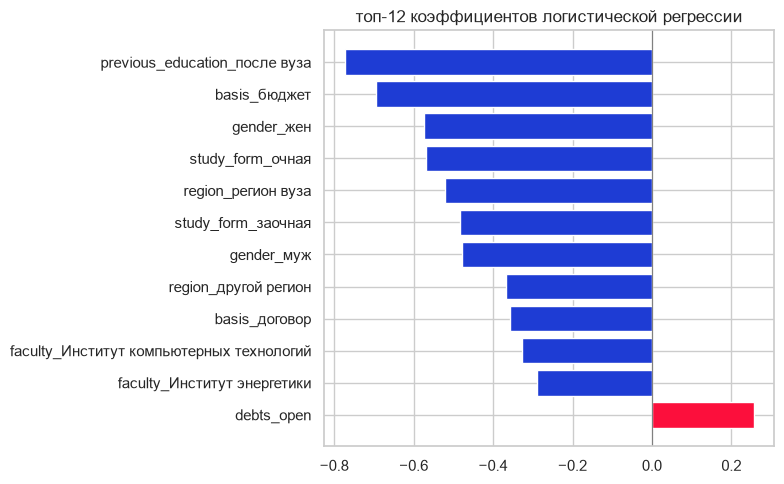

In [9]:
names = logreg.named_steps['pre'].get_feature_names_out()
coefs = logreg.named_steps['clf'].coef_[0]
coef_df = pd.DataFrame({'признак': names, 'коэффициент': coefs})
coef_df['признак'] = coef_df['признак'].str.replace(r'^(num|cat)__', '', regex=True)
top = coef_df.reindex(coef_df['коэффициент'].abs().sort_values(ascending=False).index).head(12)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#FC0F3C' if v > 0 else '#1E3CD4' for v in top['коэффициент']]
ax.barh(top['признак'][::-1], top['коэффициент'][::-1], color=colors[::-1])
ax.set_title('топ-12 коэффициентов логистической регрессии')
ax.axvline(0, c='grey', lw=0.8)
plt.tight_layout()
plt.show()

## 4. UCI: базовая модель на открытых данных

Для проверки воспроизводимости подхода та же логистическая регрессия на
UCI с фиксированным стратифицированным разделением.

In [10]:
uci = pd.read_sql('SELECT * FROM cleaned.uci_dropout', eng)
Xu = uci.drop(columns=['target_text', 'target_dropout'])
yu = uci['target_dropout'].astype(int)
from sklearn.model_selection import train_test_split
Xu_train, Xu_test, yu_train, yu_test = train_test_split(
    Xu, yu, test_size=0.3, stratify=yu, random_state=SEED)

uci_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=2000, random_state=SEED)),
])
uci_pipe.fit(Xu_train, yu_train)
proba_u = uci_pipe.predict_proba(Xu_test)[:, 1]
row_u = metrics_at(yu_test.reset_index(drop=True), proba_u, 'UCI: логистическая регрессия')
pd.DataFrame([row_u])

,модель,ROC-AUC,PR-AUC,Brier,precision@0.5,recall@0.5,recall@100,precision@100
0,UCI: логистическая регрессия,0.918,0.879,0.093,0.886,0.728,0.227,0.97


## 5. Выводы базового шага

1. Логистическая регрессия на point-in-time признаках на когорте 2023 даёт
   рабочее ранжирование: recall@100 существенно выше правила «2+ долга»,
   что уже на базовом шаге подкрепляет гипотезу H1 (полное сравнение с
   подбором гиперпараметров в notebooks/03).
2. При стандартном пороге 0.5 и дисбалансе 3.4% recall низкий: матрица
   ошибок показывает пропуски. Это ожидаемо и подтверждает выбор recall@100
   и подбор порога как рабочих инструментов (docs/requirements.md).
3. Дерево решений с ограниченной глубиной сопоставимо по ROC-AUC, но
   проигрывает по калибровке и стабильности; остаётся в наборе как
   интерпретируемая альтернатива.
4. UCI с тем же алгоритмом даёт заметно более высокие метрики: датасет
   статический и более сбалансированный (32% положительных). Синтетический
   контингент остаётся контуром проверки конвейера, главная оценка на нём
   не делается (docs/requirements.md, ограничения).
5. Ошибки: ложные тревоги концентрируются у студентов с долгами, которые
   всё же дожили до следующего семестра; пропуски у студентов с редкими
   долгами и слабой динамикой балла. Оба класса ошибок рассматриваются
   в глубокой оценке (notebooks/04).